In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("titanic.csv")

print(df.shape)
print(df.info())
print(df.isnull().sum())

(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [ ]:
data = df.copy()

data = data.drop(columns=[
    "PassengerId",
    "Name",
    "Ticket",
    "Cabin"
])

data["Age"] = data["Age"].fillna(data["Age"].median())
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

print(data.isnull().sum())

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [20]:
data = pd.get_dummies(
    data,
    drop_first=True,
    dtype=int
)

print(data.head())
print(data.columns)

   Survived  Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  \
0         0       3  22.0      1      0   7.2500         1           0   
1         1       1  38.0      1      0  71.2833         0           0   
2         1       3  26.0      0      0   7.9250         0           0   
3         1       1  35.0      1      0  53.1000         0           0   
4         0       3  35.0      0      0   8.0500         1           0   

   Embarked_S  
0           1  
1           0  
2           1  
3           1  
4           1  
Index(['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male',
       'Embarked_Q', 'Embarked_S'],
      dtype='str')


In [ ]:
X = data.drop(columns=["Survived"]).values.astype(float)
y = data["Survived"].values.astype(float)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (891, 8)
y shape: (891,)
[[ 3. 22.  1. ...  1.  0.  1.]
 [ 1. 38.  1. ...  0.  0.  0.]
 [ 3. 26.  0. ...  0.  0.  1.]
 ...
 [ 3. 28.  1. ...  0.  0.  1.]
 [ 1. 26.  0. ...  1.  0.  0.]
 [ 3. 32.  0. ...  1.  1.  0.]]


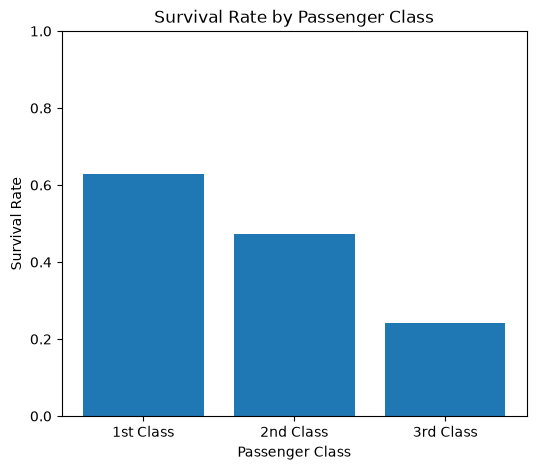

In [56]:
# Calculate survival rate for each passenger class
survival_rate = data.groupby("Pclass")["Survived"].mean()

# Plot
plt.figure(figsize=(6, 5))

plt.bar(survival_rate.index, survival_rate.values)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.xticks([1, 2, 3], ["1st Class", "2nd Class", "3rd Class"])

plt.ylim(0, 1)

plt.show()

In [37]:
np.random.seed(42)

indices = np.arange(len(X))
np.random.shuffle(indices)

split_point = int(0.8 * len(X))

train_indices = indices[:split_point]
test_indices = indices[split_point:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 712
Testing samples: 179


In [ ]:
feature_names = list(data.drop(columns=["Survived"]).columns)

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

numeric_indices = []

for feature in numeric_features:
    numeric_indices.append(feature_names.index(feature))

mean = X_train[:, numeric_indices].mean(axis=0)
std = X_train[:, numeric_indices].std(axis=0)

for i in range(len(std)):
    if std[i] == 0:
        std[i] = 1

X_train[:, numeric_indices] = (
    X_train[:, numeric_indices] - mean
) / std

# Use the same mean and std for testing data
X_test[:, numeric_indices] = (
    X_test[:, numeric_indices] - mean
) / std

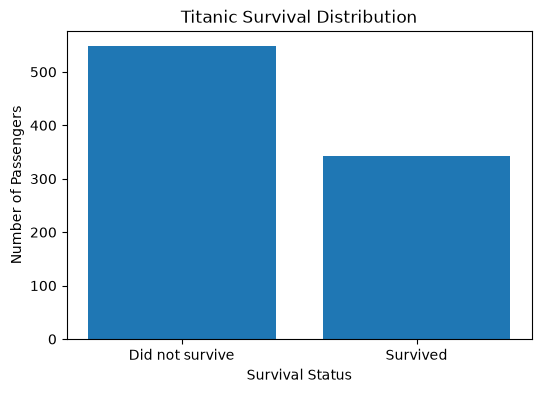

In [39]:
survival_counts = df["Survived"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Did not survive", "Survived"],
    survival_counts.values
)

plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")
plt.title("Titanic Survival Distribution")

plt.show()

In [ ]:

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def train_model(X, y, alpha, iterations):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0

    for i in range(iterations):

        z = X @ weights + bias
        predictions = sigmoid(z)

        dw = (X.T @ (predictions - y)) / n_samples
        db = np.mean(predictions - y)

        weights -= alpha * dw
        bias -= alpha * db

    return weights, bias


# Values to test
alpha_values = [0.001, 0.005, 0.01, 0.03, 0.05, 0.1, 0.2]
iteration_values = [100, 250, 500, 750, 1000, 1500, 2000, 3000]
results = []

# Test every combination
for alpha in alpha_values:

    for iterations in iteration_values:

        weights, bias = train_model(
            X_train,
            y_train,
            alpha,
            iterations
        )

        probabilities = sigmoid(
            X_test @ weights + bias
        )

        predictions = (probabilities >= 0.5).astype(int)

        accuracy = np.mean(
            predictions == y_test
        )

        results.append([
            alpha,
            iterations,
            accuracy
        ])


# Store results
results_df = pd.DataFrame(
    results,
    columns=["alpha", "iterations", "accuracy"]
)


# Find best combination
best_result = results_df.loc[
    results_df["accuracy"].idxmax()
]


print("===== HYPERPARAMETER TUNING RESULTS =====")
print(results_df)

print("\n===== OPTIMAL HYPERPARAMETERS =====")
print("Alpha:", best_result["alpha"])
print("Iterations:", int(best_result["iterations"]))
print("Accuracy:", best_result["accuracy"])

===== HYPERPARAMETER TUNING RESULTS =====
    alpha  iterations  accuracy
0   0.001         100  0.715084
1   0.001         250  0.715084
2   0.001         500  0.715084
3   0.001         750  0.720670
4   0.001        1000  0.720670
5   0.001        1500  0.720670
6   0.001        2000  0.720670
7   0.001        3000  0.720670
8   0.005         100  0.715084
9   0.005         250  0.720670
10  0.005         500  0.726257
11  0.005         750  0.709497
12  0.005        1000  0.703911
13  0.005        1500  0.715084
14  0.005        2000  0.715084
15  0.005        3000  0.726257
16  0.010         100  0.720670
17  0.010         250  0.726257
18  0.010         500  0.703911
19  0.010         750  0.715084
20  0.010        1000  0.715084
21  0.010        1500  0.726257
22  0.010        2000  0.731844
23  0.010        3000  0.743017
24  0.030         100  0.720670
25  0.030         250  0.715084
26  0.030         500  0.726257
27  0.030         750  0.743017
28  0.030        1000  0.74301

In [41]:
alpha = 0.05
iterations = 3000

class LogisticRegressionScratch:

    def __init__(self, alpha=0.05, iterations=3000):

        self.alpha = alpha
        self.iterations = iterations

        self.weights = None
        self.bias = 0

        self.cost_history = []


    def sigmoid(self, z):

        z = np.clip(z, -500, 500)

        return 1 / (1 + np.exp(-z))


    def compute_cost(self, X, y):

        predictions = self.sigmoid(
            X @ self.weights + self.bias
        )

        epsilon = 1e-15

        predictions = np.clip(
            predictions,
            epsilon,
            1 - epsilon
        )

        cost = -np.mean(
            y * np.log(predictions)
            + (1 - y) * np.log(1 - predictions)
        )

        return cost


    def fit(self, X, y):

        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)
        self.bias = 0

        for i in range(self.iterations):

            # Forward propagation
            z = X @ self.weights + self.bias

            predictions = self.sigmoid(z)

            # Gradients
            dw = (
                X.T @ (predictions - y)
            ) / n_samples

            db = np.mean(
                predictions - y
            )

            # Update parameters
            self.weights -= self.alpha * dw

            self.bias -= self.alpha * db

            # Store cost
            cost = self.compute_cost(X, y)

            self.cost_history.append(cost)

        return self


    def predict_proba(self, X):

        z = X @ self.weights + self.bias

        return self.sigmoid(z)


    def predict(self, X, threshold=0.5):

        probabilities = self.predict_proba(X)

        return (
            probabilities >= threshold
        ).astype(int)

In [42]:
model = LogisticRegressionScratch(
    alpha=0.05,
    iterations=3000
)

model.fit(X_train, y_train)

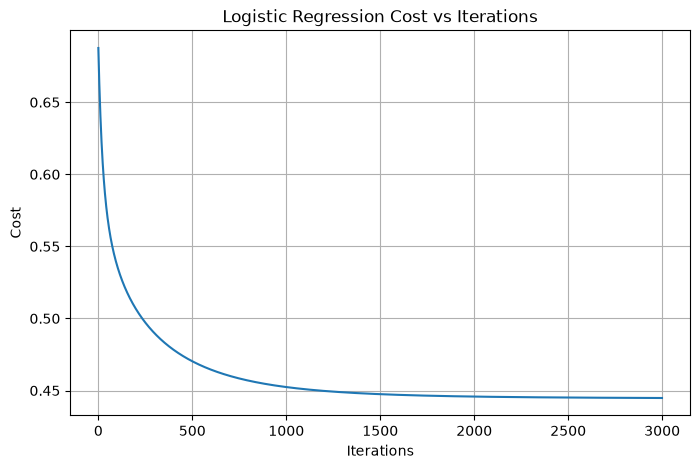

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    model.cost_history
)

plt.xlabel("Iterations")
plt.ylabel("Cost")

plt.title(
    "Logistic Regression Cost vs Iterations"
)

plt.grid(True)

plt.show()

In [44]:
def calculate_metrics(y_actual, y_pred):

    TP = np.sum(
        (y_pred == 1) &
        (y_actual == 1)
    )

    TN = np.sum(
        (y_pred == 0) &
        (y_actual == 0)
    )

    FP = np.sum(
        (y_pred == 1) &
        (y_actual == 0)
    )

    FN = np.sum(
        (y_pred == 0) &
        (y_actual == 1)
    )

    accuracy = (
        (TP + TN) /
        (TP + TN + FP + FN)
    )

    precision = (
        TP / (TP + FP)
        if TP + FP != 0 else 0
    )

    recall = (
        TP / (TP + FN)
        if TP + FN != 0 else 0
    )

    f1 = (
        2 * precision * recall /
        (precision + recall)
        if precision + recall != 0 else 0
    )

    return accuracy, precision, recall, f1

In [45]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [46]:
train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(
    y_train,
    y_train_pred
)

test_accuracy, test_precision, test_recall, test_f1 = calculate_metrics(
    y_test,
    y_test_pred
)

print("Training Metrics")
print("Accuracy :", train_accuracy)
print("Precision:", train_precision)
print("Recall   :", train_recall)
print("F1 Score :", train_f1)

print("\nTesting Metrics")
print("Accuracy :", test_accuracy)
print("Precision:", test_precision)
print("Recall   :", test_recall)
print("F1 Score :", test_f1)

Training Metrics
Accuracy : 0.797752808988764
Precision: 0.7509433962264151
Recall   : 0.7184115523465704
F1 Score : 0.7343173431734317

Testing Metrics
Accuracy : 0.776536312849162
Precision: 0.6865671641791045
Recall   : 0.7076923076923077
F1 Score : 0.696969696969697


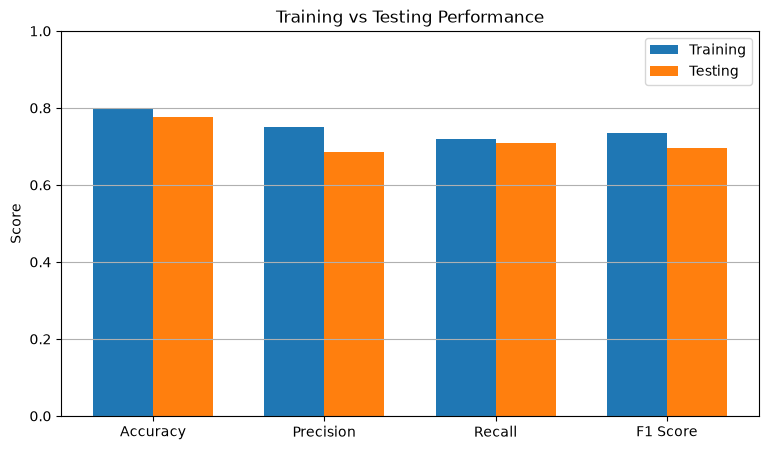

In [47]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

train_values = [
    train_accuracy,
    train_precision,
    train_recall,
    train_f1
]

test_values = [
    test_accuracy,
    test_precision,
    test_recall,
    test_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    train_values,
    width,
    label="Training"
)

plt.bar(
    x + width / 2,
    test_values,
    width,
    label="Testing"
)

plt.xticks(x, metrics)

plt.ylabel("Score")
plt.ylim(0, 1)

plt.title(
    "Training vs Testing Performance"
)

plt.legend()
plt.grid(axis="y")

plt.show()

In [48]:
test_TP = np.sum(
    (y_test_pred == 1) &
    (y_test == 1)
)

test_TN = np.sum(
    (y_test_pred == 0) &
    (y_test == 0)
)

test_FP = np.sum(
    (y_test_pred == 1) &
    (y_test == 0)
)

test_FN = np.sum(
    (y_test_pred == 0) &
    (y_test == 1)
)

test_cm = np.array([
    [test_TN, test_FP],
    [test_FN, test_TP]
])

print("Testing Confusion Matrix:")
print(test_cm)

Testing Confusion Matrix:
[[93 21]
 [19 46]]


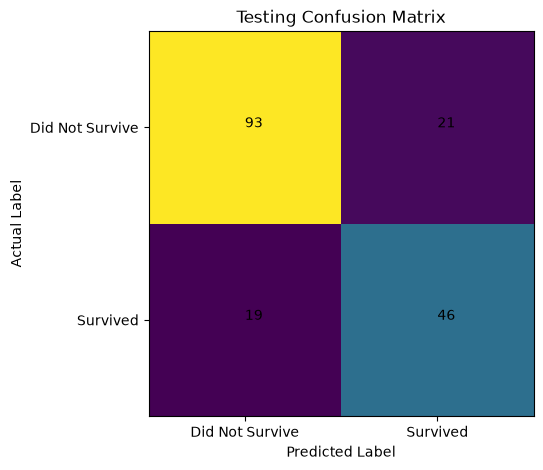

In [55]:
plt.figure(figsize=(6, 5))

plt.imshow(test_cm)

plt.title("Testing Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Did Not Survive", "Survived"])
plt.yticks([0, 1], ["Did Not Survive", "Survived"])

# Display the values inside the matrix
plt.text(0, 0, test_cm[0, 0])
plt.text(1, 0, test_cm[0, 1])
plt.text(0, 1, test_cm[1, 0])
plt.text(1, 1, test_cm[1, 1])


plt.show()